# War & Oil Stock Price · 탐색 노트

제공된 과거 분석을 재구성하고 이번 수집 결과와 구분했습니다. 먼저 저장소 루트에서 `python scripts/run_analysis.py`를 실행한 뒤 전 셀을 위에서 아래로 실행합니다. 데이터 수집·계산 로직은 공통 모듈에서 관리합니다.

사건 기준일은 2026-02-28이며 미국 3/2·한국 3/3 종가를 2/27 종가와 비교했습니다. [출처와 미확인 사항](../docs/sources.md)을 함께 기록했습니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "configs/analysis.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/processed/run_manifest.json").exists(), "먼저 scripts/run_analysis.py를 실행하세요."
manifest = json.loads((ROOT / "data/processed/run_manifest.json").read_text(encoding="utf-8"))
display({"status": manifest["status"], "completed_at_utc": manifest["completed_at_utc"], "versions": manifest["versions"]})

{'status': 'complete',
 'completed_at_utc': '2026-11-11T18:37:11.571664+00:00',
 'versions': {'python': '3.10.11',
  'pandas': '2.3.3',
  'numpy': '2.2.6',
  'matplotlib': '3.10.9',
  'yfinance': '1.8.0',
  'requests': '2.34.2'}}

## 1. 표본과 기간

초기 미국 21개, TPL 제외 주 비교 20개, 매출 입력 18개를 구분했습니다. 한국 13개는 후속 검색에서 제공된 표본이며 전수성을 검증하지 않았습니다. 기간 끝은 배타적으로 해석했습니다.

In [2]:
audit = pd.read_csv(ROOT / "data/processed/acquisition_manifest.csv")
display(audit.groupby("window", sort=False).agg(requested_start=("requested_start", "first"), end_exclusive=("end_exclusive", "first"), actual_first_date=("actual_first_date", "min"), actual_last_date=("actual_last_date", "max"), tickers=("ticker", "size")))
display(pd.read_csv(ROOT / "data/processed/daily_baselines.csv"))
display(pd.read_csv(ROOT / "data/processed/company_verification.csv", dtype={"expected_code":str,"provider_code":str}))

,requested_start,end_exclusive,actual_first_date,actual_last_date,tickers
window,,,,,
oil_long,2026-02-01,2026-04-01,2026-02-02,2026-03-31,2
oil_short,2026-02-24,2026-03-16,2026-02-24,2026-03-13,2
us_three_dates,2026-02-25,2026-03-15,2026-02-25,2026-03-13,21
us_daily,2026-02-01,2026-04-02,2026-02-02,2026-04-01,21
kr_daily,2026-02-01,2026-04-02,2026-02-02,2026-04-01,13


,window,requested_start,baseline_date,rule
0,us_daily,2026-02-01,2026-02-02,first_observed_row_in_market_window_not_event_...
1,kr_daily,2026-02-01,2026-02-02,first_observed_row_in_market_window_not_event_...


,ticker,expected_company,provider_company,expected_code,provider_code,expected_market,provider_market,status,url,fetched_at_utc,error
0,010950.KS,S-Oil,S-Oil,010950,010950,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
1,014530.KS,극동유화,극동유화,014530,014530,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
2,002420.KS,세기상사,우양피앤엘,002420,002420,KOSPI,KOSPI,verified_code_market_current_name_differs,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
3,128820.KS,대성산업,대성산업,128820,128820,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
4,078930.KS,GS,GS,078930,078930,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
5,096770.KS,SK이노베이션,SK이노베이션,096770,096770,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
6,025860.KS,남해화학,남해화학,025860,025860,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
7,267250.KS,HD현대,HD현대,267250,267250,KOSPI,KOSPI,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:54.454675+00:00,NaN
8,024060.KQ,흥구석유,흥구석유,024060,024060,KOSDAQ,KOSDAQ,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:55.807855+00:00,NaN
9,000440.KQ,중앙에너비스,중앙에너비스,000440,000440,KOSDAQ,KOSDAQ,verified_KIND_current,https://kind.krx.co.kr/corpgeneral/corpList.do...,2026-11-11T18:26:55.807855+00:00,NaN


## 2. 사건 직후 기업별 반응

정확한 기준일 종가를 사용했고 휴장일을 채우지 않았습니다. 다음 표와 그래프는 이번 실행 결과이며 사용자가 과거 관찰했다고 설명한 수치와 동일함을 보증하지 않았습니다.

,ticker,company,baseline_date,reaction_date,return_pct,include_main,status
0,XOM,ExxonMobil,2026-02-27,2026-03-02,1.127870,True,ok
1,CVX,Chevron Corporation,2026-02-27,2026-03-02,1.520674,True,ok
2,COP,ConocoPhillips,2026-02-27,2026-03-02,4.212937,True,ok
3,WMB,Williams Companies,2026-02-27,2026-03-02,2.061029,True,ok
4,SLB,Schlumberger,2026-02-27,2026-03-02,-0.136345,True,ok
5,KMI,Kinder Morgan,2026-02-27,2026-03-02,1.863537,True,ok
6,VLO,Valero Energy,2026-02-27,2026-03-02,5.018571,True,ok
7,MPC,Marathon Petroleum,2026-02-27,2026-03-02,5.857424,True,ok
8,EOG,EOG Resources,2026-02-27,2026-03-02,3.683101,True,ok
9,PSX,Phillips 66,2026-02-27,2026-03-02,3.790573,True,ok


,ticker,baseline_date,reaction_date,baseline_close,reaction_close,return_pct
0,BZ=F,2026-02-27,2026-03-02,72.480003,77.739998,7.257166
1,CL=F,2026-02-27,2026-03-02,67.019997,71.230003,6.281717


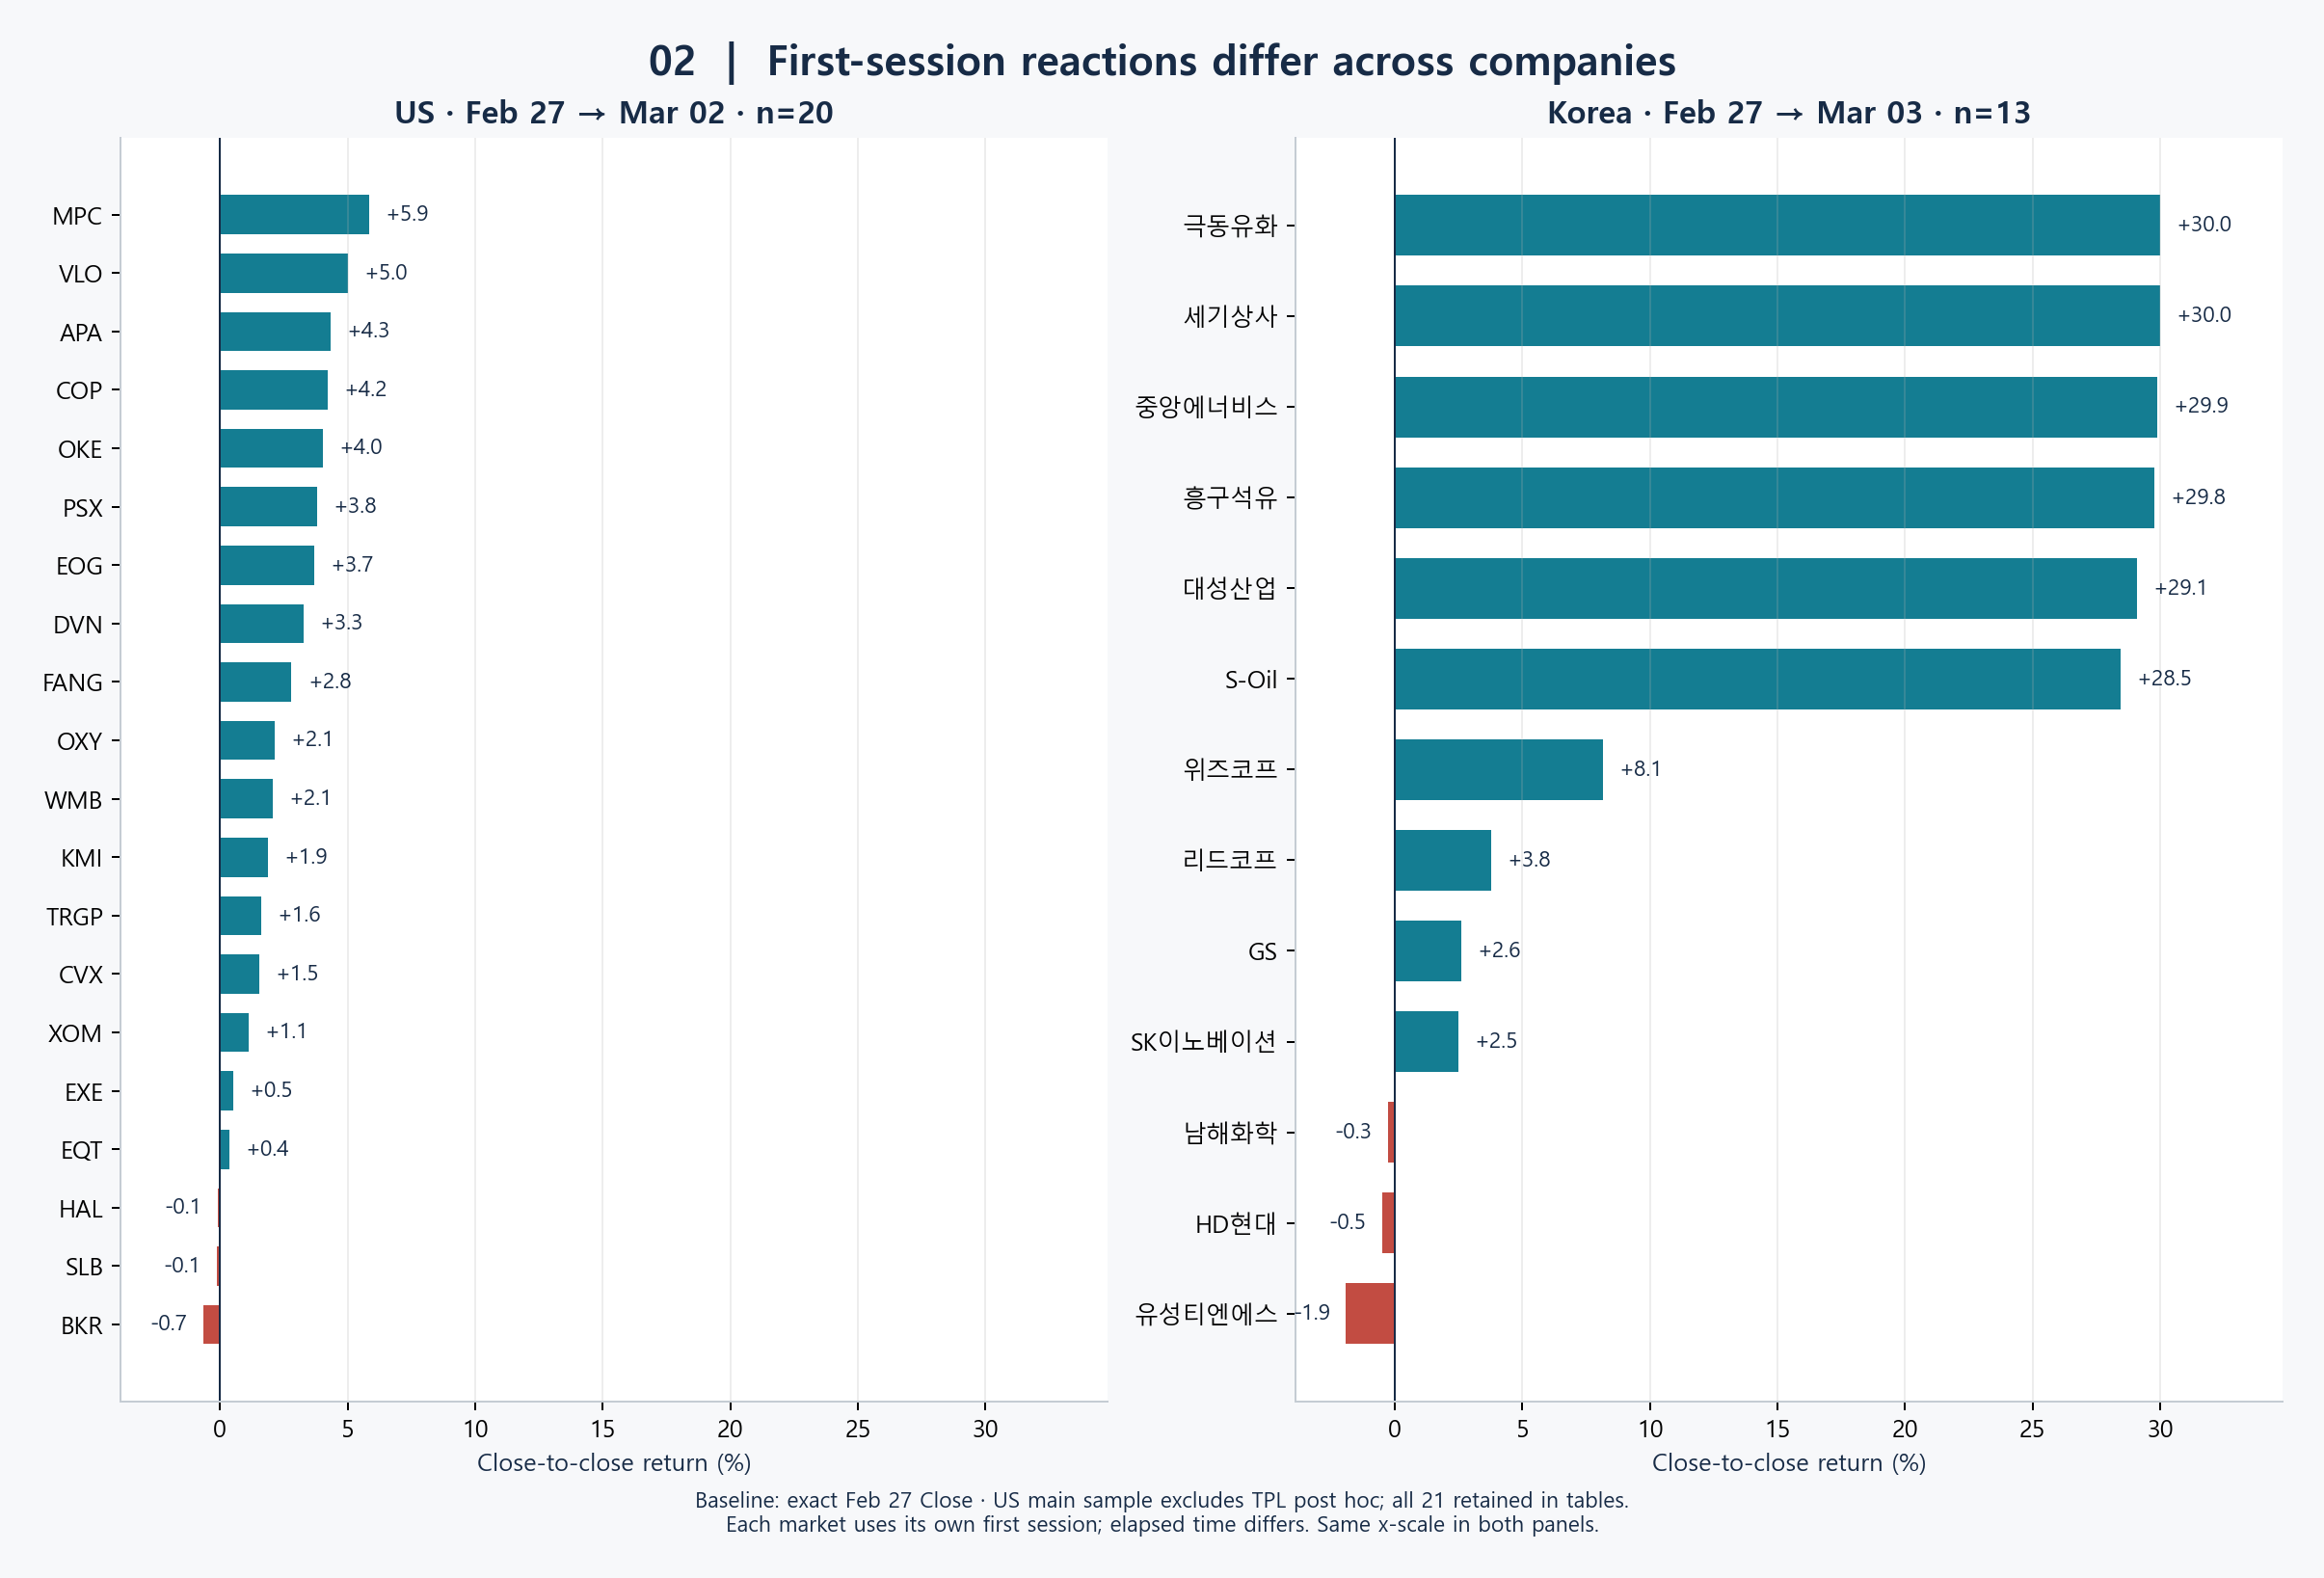

In [3]:
reactions = pd.read_csv(ROOT / "data/processed/event_reactions.csv")
display(reactions[["ticker", "company", "baseline_date", "reaction_date", "return_pct", "include_main", "status"]])
display(pd.read_csv(ROOT / "data/processed/oil_event_reactions.csv"))
display(Image(filename=str(ROOT / "reports/figures/event_reactions.png"), width=1000))

## 3. 선물과 세부 업종의 흐름

선물은 현물과 구분했습니다. 업종별 그림은 2/27 기준 수익률에 공통 y축을 사용했습니다. 장기 첫 관측일 2/2 기준의 21개 그림은 보고서 부록에 별도로 남겼습니다.

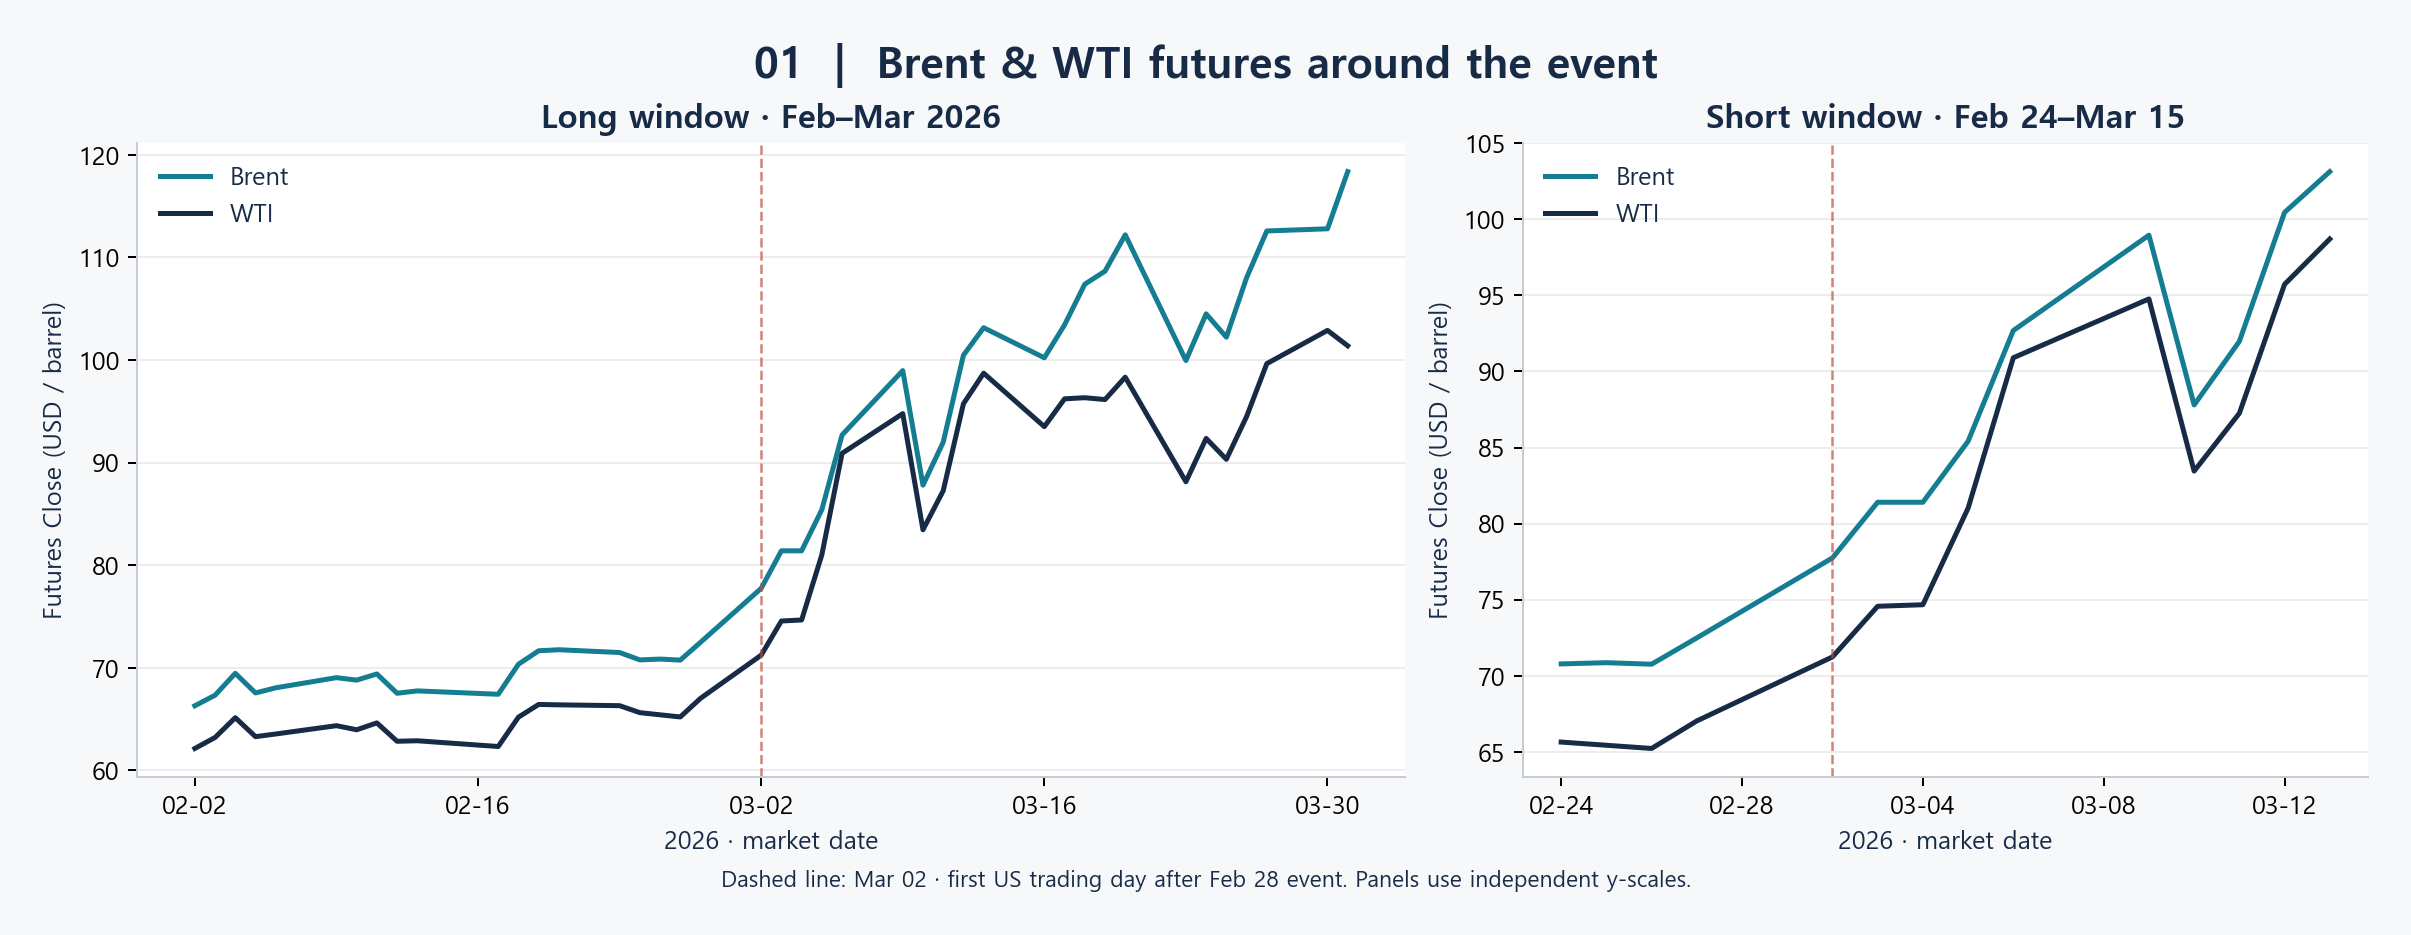

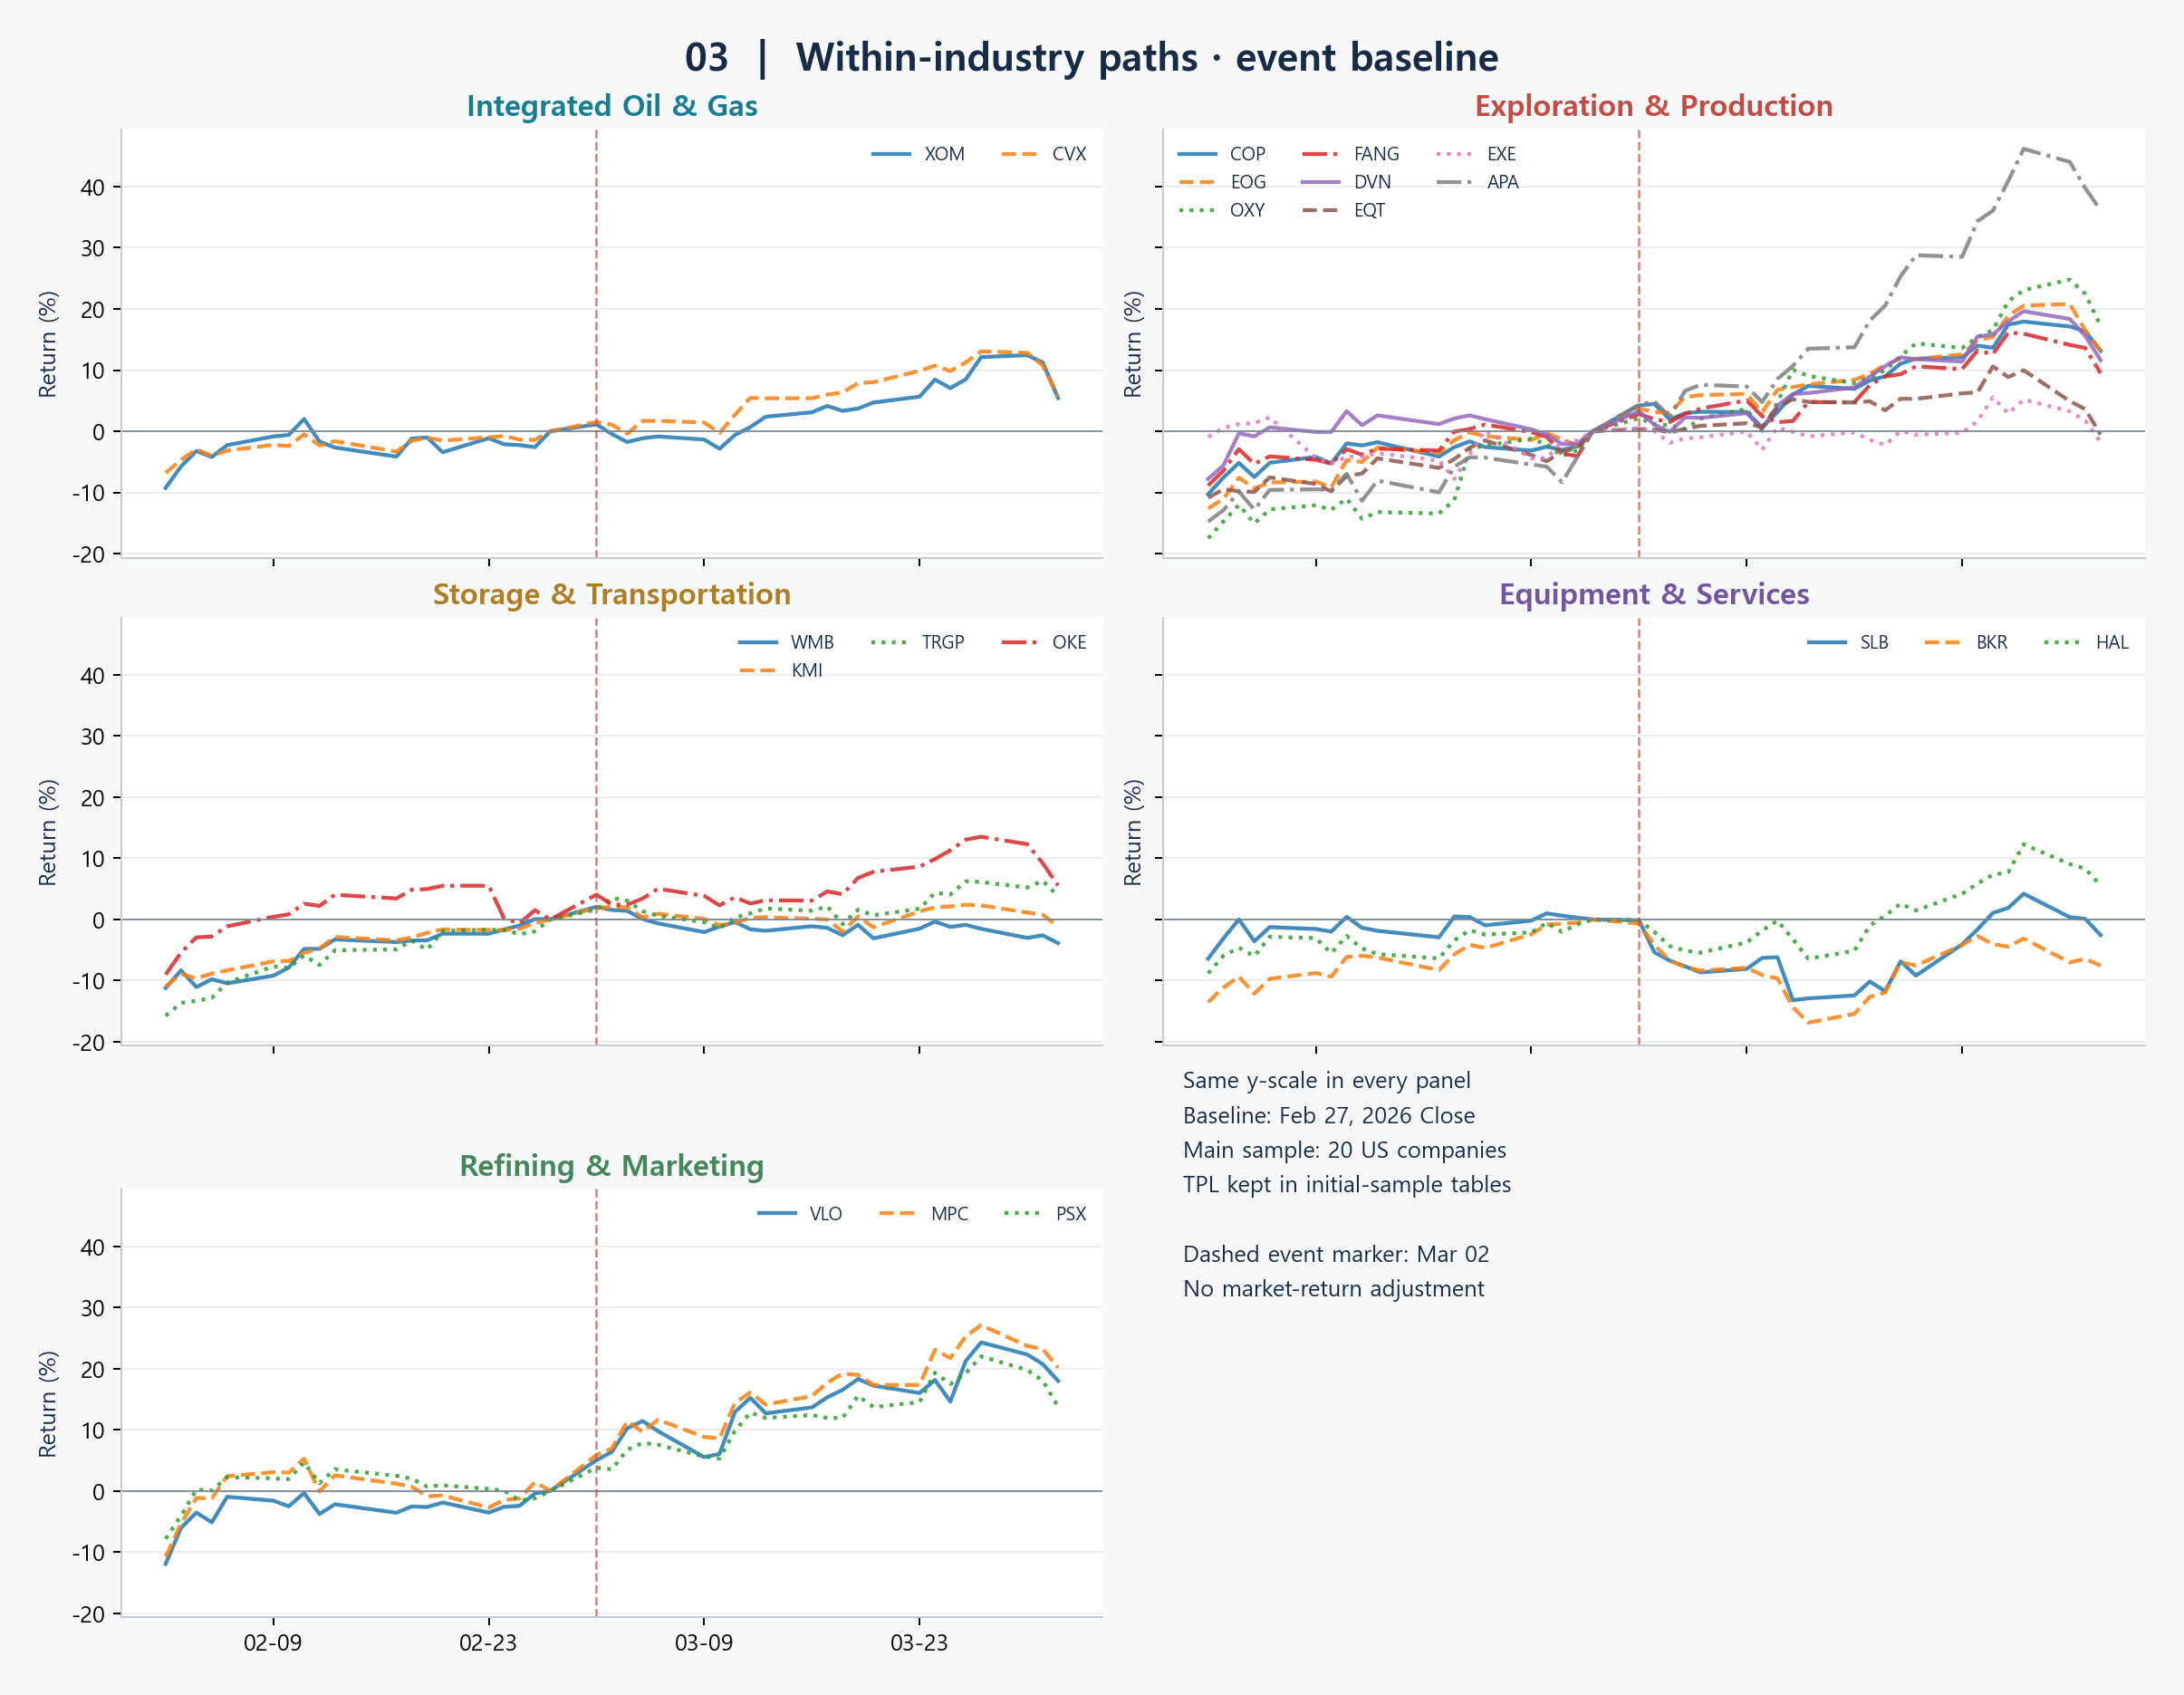

,sub_industry,available_n,mean_return_pct,min_return_pct,max_return_pct
0,Integrated Oil & Gas,2,1.324272,1.127870,1.520674
1,Oil & Gas Equipment & Services,3,-0.292860,-0.658903,-0.083330
2,Oil & Gas Exploration & Production,8,2.665385,0.358192,4.346393
3,Oil & Gas Refining & Marketing,3,4.888856,3.790573,5.857424
4,Oil & Gas Storage & Transportation,4,2.396927,1.615775,4.047368


,sample,n,available_n,positive_n,equal_company_mean_return_pct
0,initial_21,21,21,18,2.316397
1,main_20_without_TPL,20,20,17,2.367366


In [4]:
display(Image(filename=str(ROOT / "reports/figures/oil_windows.png"), width=1000))
display(Image(filename=str(ROOT / "reports/figures/us_industries.png"), width=1000))
display(pd.read_csv(ROOT / "data/processed/us_industry_first_session_summary.csv"))
display(pd.read_csv(ROOT / "data/processed/tpl_sample_sensitivity.csv"))

## 4. HD현대에서 사업 구성 질문으로

HD현대 조선해양 41.8%·정유 38.5%는 사용자 제공 입력입니다. 매출 구성이 주가 하락의 원인임을 검증하지 않았습니다. 기타 0.38%에 대한 설명은 캡처 없는 전사 정보로만 남겼고 원 입력에 추가하지 않았습니다.

,segment,pct,classification,period
45,조선해양,41.8,other_explicit,2025.12_user_transcription
46,정유,38.5,oil_gas_explicit,2025.12_user_transcription
47,건설기계,11.5,other_explicit,2025.12_user_transcription
48,전기전자,5.3,other_explicit,2025.12_user_transcription
49,선박서비스,2.5,other_explicit,2025.12_user_transcription


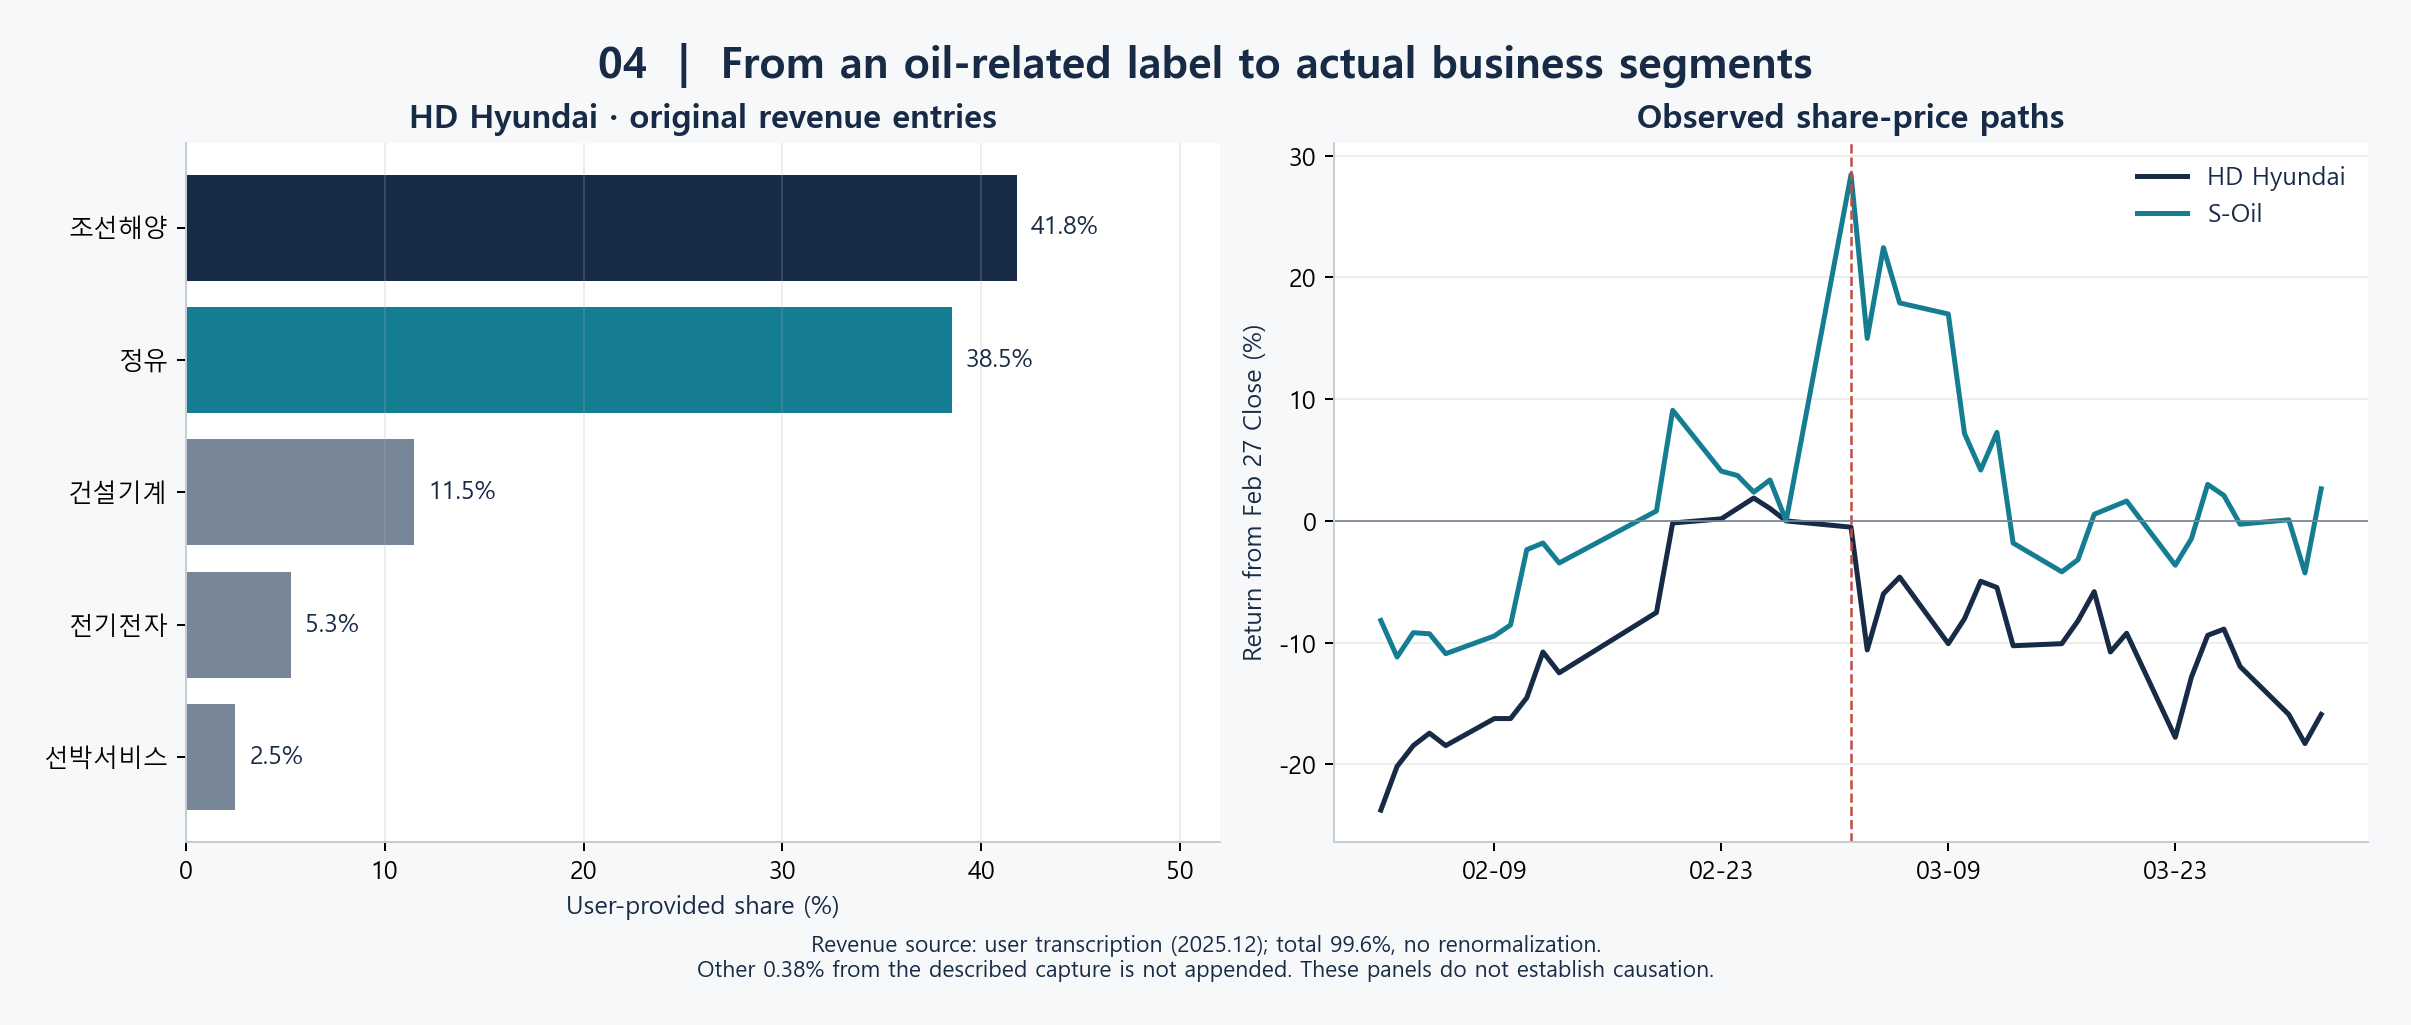

,ticker,company,total_pct,delta_from_100,negative_count,missing_count,review_segments,sum_status
0,010950.KS,S-Oil,80.1,-19.9,0,0,0,review
12,267250.KS,HD현대,99.6,-0.4,0,0,0,review
15,SLB,슐럼버거,102.7,2.7,0,0,1,review
18,DVN,데본 에너지,92.8,-7.2,0,0,1,review
27,WMB,윌리엄스 컴퍼니스,112.0,12.0,0,0,1,review
30,OKE,원오크,129.5,29.5,0,0,1,review


In [5]:
revenue = pd.read_csv(ROOT / "data/reference/revenue_segments.csv")
display(revenue[revenue.ticker == "267250.KS"][["segment", "pct", "classification", "period"]])
display(Image(filename=str(ROOT / "reports/figures/hd_hyundai_case.png"), width=1000))
quality = pd.read_csv(ROOT / "data/processed/revenue_quality.csv")
display(quality[quality.sum_status == "review"])

## 5. 해석의 범위

원 입력의 음수·100% 초과·부분 제공 상태를 보존했습니다. 국가별 매출 비중을 파이로 합산하거나 불완전한 입력으로 다각화 지수를 만들지 않았습니다. TPL은 사후 사업 모델 비교 가능성 판단으로 주 비교에서 제외했으며 초기 표본의 자료를 유지했습니다. COP·APA의 매출 누락 이유는 미제공으로 남겼습니다.

단일 사건, 국가별 시간 차이, 시장 수익률과 기업 특성 미통제, 사후 가설 형성을 한계로 기록했습니다. 통계 검정·ML·인과 추론은 수행하지 않았습니다. 코드 테스트와 경제적 가설 검증은 구분했습니다. [상세 분석](../reports/analysis.md)과 [품질 보고서](../reports/data_quality.md)에서 근거와 제한을 정리했습니다.